# LAB 1 — Implementation and Performance Analysis of Q-Learning Using an Epsilon-Greedy Policy

**Environment:** `CliffWalking-v1` (Gymnasium) — a discrete-state, discrete-action grid-world environment.

### Imports

In [4]:
import numpy as np
import gymnasium as gym
import random
import matplotlib.pyplot as plt
from tqdm import trange

RNG_SEED = 42
np.random.seed(RNG_SEED)
random.seed(RNG_SEED)

In [5]:
import sys
!{sys.executable} -m pip install imageio pygame


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


### Environment Setup

In [6]:
env = gym.make("CliffWalking-v1")

print("Observation Space:", env.observation_space)
print("Sample observation:", env.observation_space.sample())
print("Action Space Shape:", env.action_space.n)
print("Action Space Sample:", env.action_space.sample())

state_space = env.observation_space.n
action_space = env.action_space.n

print("There are", state_space, "possible states")
print("There are", action_space, "possible actions")

# Action meanings for CliffWalking-v1: 0 = Up, 1 = Right, 2 = Down, 3 = Left
ACTION_NAMES = {0: "Up", 1: "Right", 2: "Down", 3: "Left"}
ACTION_ARROWS = {0: "^", 1: ">", 2: "v", 3: "<"}
GRID_ROWS, GRID_COLS = 4, 12
GOAL_STATE = GRID_ROWS * GRID_COLS - 1 
CLIFF_STATES = set(range(37, 47))       
START_STATE = 36

Observation Space: Discrete(48)
Sample observation: 29
Action Space Shape: 4
Action Space Sample: 1
There are 48 possible states
There are 4 possible actions


### Q-table Initialization

In [7]:
def initialize_q_table(state_space, action_space):
    return np.zeros((state_space, action_space))

Qtable_demo = initialize_q_table(state_space, action_space)
print("Q-table shape:", Qtable_demo.shape)
Qtable_demo

Q-table shape: (48, 4)


array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 0.],


## 1. Train the agent using different numbers of training episodes and compare its learning performance.

Use the following training configurations:

500, 1,000, 2,000, 5,000, and 10,000 episodes.

In [8]:
# Training configurations
EPISODE_CONFIGS = [500, 1000, 2000, 5000, 10000]

# Q-learning hyperparameters
learning_rate = 0.7
gamma = 0.95

max_epsilon = 1.0
min_epsilon = 0.05
decay_rate = 0.0005

# Environment parameters
max_steps = 200       

# Evaluation parameters
n_eval_episodes = 100

## 2. Start with a high value of epsilon to encourage exploration.

In [9]:
epsilon = max_epsilon

print("Initial epsilon:", epsilon)

Initial epsilon: 1.0


## 3. Gradually decrease epsilon during training.

In [10]:
#Epsilon-Greedy and Greedy Policies
def epsilon_greedy_policy(Qtable, state, epsilon, env):
    """With probability (1 - epsilon) exploit the best known action,
    otherwise explore with a random action."""
    random_value = random.uniform(0, 1)
    if random_value > epsilon:
        action = np.argmax(Qtable[state])
    else:
        action = env.action_space.sample()
    return action


def greedy_policy(Qtable, state):
    """Pure exploitation: used during evaluation, no exploration."""
    return np.argmax(Qtable[state])

## 4. Record the total reward obtained in every episode.

In [11]:
#Q-Learning Training Function
def train(n_training_episodes, min_epsilon, max_epsilon, decay_rate,
          env, max_steps, Qtable, learning_rate, gamma):
    episode_rewards = []

    for episode in trange(n_training_episodes, desc=f"Training ({n_training_episodes} episodes)"):

        # Epsilon decay: starts near max_epsilon, decays exponentially toward min_epsilon
        epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)

        state, info = env.reset()
        total_reward = 0

        for step in range(max_steps):

            action = epsilon_greedy_policy(Qtable, state, epsilon, env)

            new_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # Q-learning update rule
            Qtable[state, action] = Qtable[state, action] + learning_rate * (
                reward + gamma * np.max(Qtable[new_state]) * (not terminated) - Qtable[state, action]
            )

            state = new_state
            total_reward += reward

            if done:
                break

        episode_rewards.append(total_reward)

    return Qtable, episode_rewards

### Run Training for All Configurations

This loop implements Tasks 1 and 4 together: it trains a fresh agent for each episode configuration (Task 1) and records the reward of every training episode (Task 4).

In [12]:
results = {}     # episodes -> dict with Qtable, episode_rewards (evaluation results added later)

for n_episodes in EPISODE_CONFIGS:
    print(f"\n=== Training configuration: {n_episodes} episodes ===")

    env = gym.make("CliffWalking-v1")
    Qtable = initialize_q_table(state_space, action_space)

    Qtable, episode_rewards = train(
        n_episodes, min_epsilon, max_epsilon, decay_rate,
        env, max_steps, Qtable, learning_rate, gamma
    )

    results[n_episodes] = {
        "Qtable": Qtable,
        "episode_rewards": episode_rewards,
    }

    print(f"Training reward (last 100 episodes avg): {np.mean(episode_rewards[-100:]):.2f}")

    env.close()



=== Training configuration: 500 episodes ===


Training (500 episodes): 100%|██████████████| 500/500 [00:01<00:00, 490.79it/s]


Training reward (last 100 episodes avg): -1010.54

=== Training configuration: 1000 episodes ===


Training (1000 episodes): 100%|███████████| 1000/1000 [00:01<00:00, 635.74it/s]


Training reward (last 100 episodes avg): -470.72

=== Training configuration: 2000 episodes ===


Training (2000 episodes): 100%|███████████| 2000/2000 [00:02<00:00, 995.68it/s]


Training reward (last 100 episodes avg): -191.75

=== Training configuration: 5000 episodes ===


Training (5000 episodes): 100%|██████████| 5000/5000 [00:02<00:00, 1860.28it/s]


Training reward (last 100 episodes avg): -66.28

=== Training configuration: 10000 episodes ===


Training (10000 episodes): 100%|███████| 10000/10000 [00:03<00:00, 2913.73it/s]

Training reward (last 100 episodes avg): -28.80


## 5 & 6. Calculate the Cumulative Reward and Plot It Against Training Episodes.

The cumulative reward per configuration is the running sum (`np.cumsum`) of the per-episode training rewards recorded in Task 4.

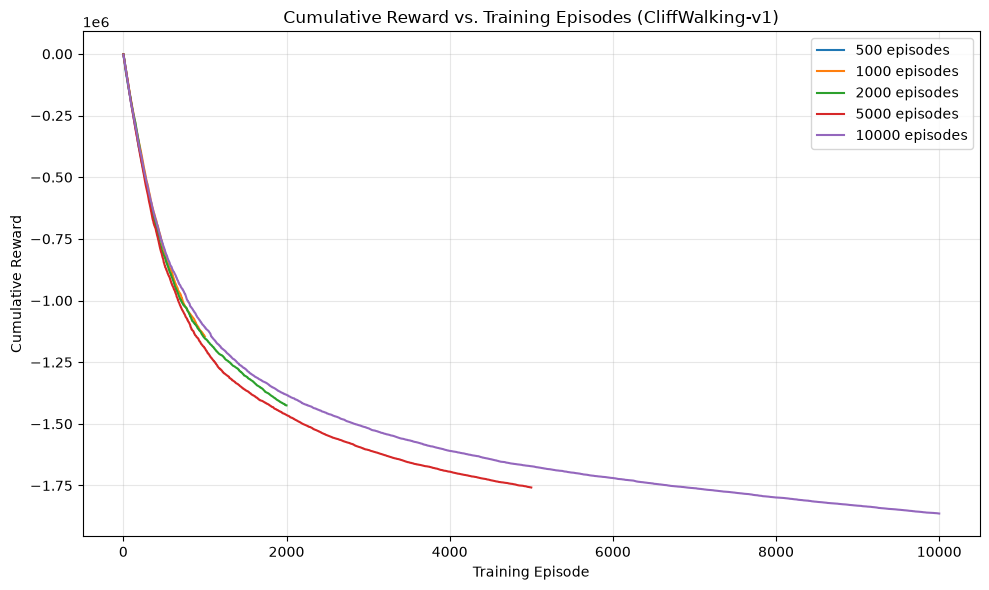

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
for n_episodes in EPISODE_CONFIGS:
    rewards = results[n_episodes]["episode_rewards"]
    cumulative_reward = np.cumsum(rewards)
    ax.plot(range(1, len(cumulative_reward) + 1), cumulative_reward, label=f"{n_episodes} episodes")

#Cumulative Reward vs. Training Episodes
ax.set_xlabel("Training Episode")
ax.set_ylabel("Cumulative Reward")
ax.set_title("Cumulative Reward vs. Training Episodes (CliffWalking-v1)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cumulative Reward: Shows the total reward accumulated during training, becoming more negative as the number of episodes increases.

## 7. After each training configuration, test the learned policy for 100 episodes without exploration.

In [14]:
#Evaluation Function
def evaluate_agent(env, max_steps, n_eval_episodes, Qtable, seeds=None):
    episode_rewards = []
    successes = 0

    for episode in range(n_eval_episodes):
        if seeds is not None:
            state, info = env.reset(seed=seeds[episode])
        else:
            state, info = env.reset()

        total_reward = 0
        episode_terminated = False

        for step in range(max_steps):
            action = greedy_policy(Qtable, state)
            new_state, reward, terminated, truncated, info = env.step(action)

            total_reward += reward
            state = new_state

            if terminated:
                episode_terminated = True

            if terminated or truncated:
                break

        if episode_terminated:
            successes += 1

        episode_rewards.append(total_reward)

    mean_reward = np.mean(episode_rewards)
    std_reward = np.std(episode_rewards)
    success_rate = (successes / n_eval_episodes) * 100   # based on terminated flag, NOT reward magnitude

    return mean_reward, std_reward, success_rate

In [15]:
eval_rng = np.random.default_rng(RNG_SEED)
eval_seeds = eval_rng.integers(low=0, high=1_000_000, size=n_eval_episodes).tolist()

eval_env = gym.make("CliffWalking-v1")

for n_episodes in EPISODE_CONFIGS:
    Qtable = results[n_episodes]["Qtable"]

    mean_reward, std_reward, success_rate = evaluate_agent(
        eval_env, max_steps, n_eval_episodes, Qtable, seeds=eval_seeds
    )

    results[n_episodes]["mean_reward"] = mean_reward
    results[n_episodes]["std_reward"] = std_reward
    results[n_episodes]["success_rate"] = success_rate

    print(f"{n_episodes} training episodes -> mean reward: {mean_reward:.2f}, std: {std_reward:.2f}, success rate: {success_rate:.2f}%")

eval_env.close()


500 training episodes -> mean reward: -13.00, std: 0.00, success rate: 100.00%
1000 training episodes -> mean reward: -13.00, std: 0.00, success rate: 100.00%
2000 training episodes -> mean reward: -13.00, std: 0.00, success rate: 100.00%
5000 training episodes -> mean reward: -13.00, std: 0.00, success rate: 100.00%
10000 training episodes -> mean reward: -13.00, std: 0.00, success rate: 100.00%


## 8. Calculate and compare the success rate.

In [16]:
print(f"{'Episodes':>10} | {'Mean Eval Reward':>18} | {'Std Reward':>10} | {'Success Rate (%)':>18}")
print("-" * 65)
for n_episodes in EPISODE_CONFIGS:
    r = results[n_episodes]
    print(f"{n_episodes:>10} | {r['mean_reward']:>18.2f} | {r['std_reward']:>10.2f} | {r['success_rate']:>18.2f}")

  Episodes |   Mean Eval Reward | Std Reward |   Success Rate (%)
-----------------------------------------------------------------
       500 |             -13.00 |       0.00 |             100.00
      1000 |             -13.00 |       0.00 |             100.00
      2000 |             -13.00 |       0.00 |             100.00
      5000 |             -13.00 |       0.00 |             100.00
     10000 |             -13.00 |       0.00 |             100.00


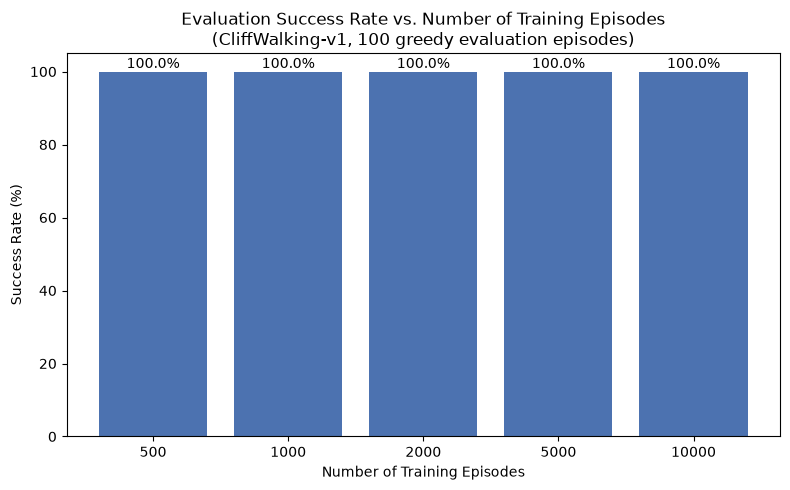

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
success_rates = [results[n]["success_rate"] for n in EPISODE_CONFIGS]
bars = ax.bar([str(n) for n in EPISODE_CONFIGS], success_rates, color="#4C72B0")
ax.set_xlabel("Number of Training Episodes")
ax.set_ylabel("Success Rate (%)")
ax.set_title("Evaluation Success Rate vs. Number of Training Episodes\n(CliffWalking-v1, 100 greedy evaluation episodes)")
ax.set_ylim(0, 105)
for bar, rate in zip(bars, success_rates):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 1, f"{rate:.1f}%", ha="center")
plt.tight_layout()
plt.show()

Success Rate: All five configurations achieved a 100% success rate over 100 evaluation episodes.

## 9. Because the cumulative reward normally keeps increasing, also plot the average reward over the most recent 100 episodes.

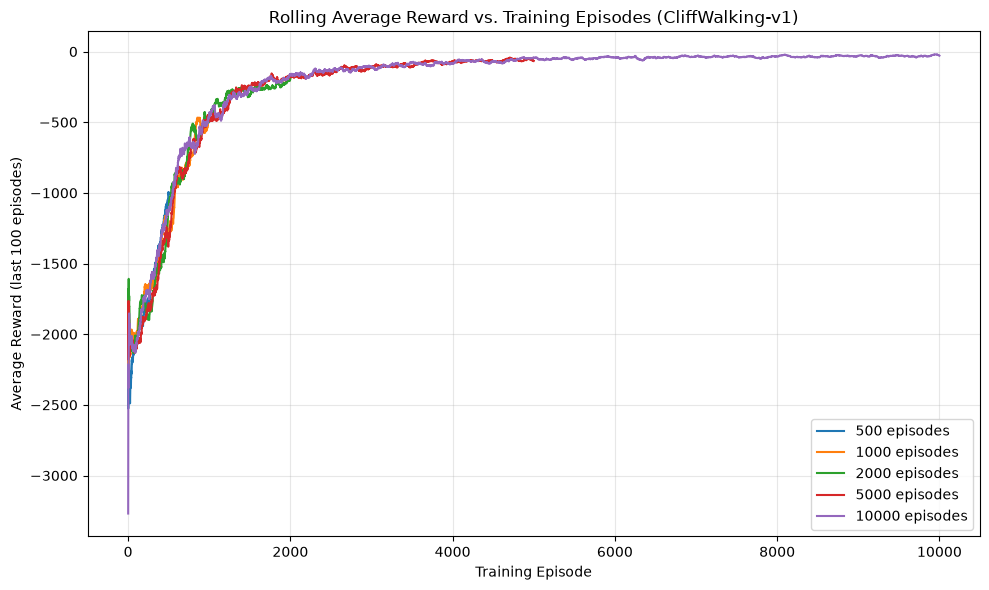

In [18]:
def rolling_average(values, window=100):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        window = len(values)
    cumsum = np.cumsum(np.insert(values, 0, 0))
    rolled = (cumsum[window:] - cumsum[:-window]) / window
    # pad the front so the array aligns with episode indices, using expanding-window average
    front = [np.mean(values[:i + 1]) for i in range(window - 1)]
    return np.concatenate([front, rolled])

fig, ax = plt.subplots(figsize=(10, 6))
for n_episodes in EPISODE_CONFIGS:
    rewards = results[n_episodes]["episode_rewards"]
    avg_last_100 = rolling_average(rewards, window=100)
    ax.plot(range(1, len(avg_last_100) + 1), avg_last_100, label=f"{n_episodes} episodes")

ax.set_xlabel("Training Episode")
ax.set_ylabel("Average Reward (last 100 episodes)")
ax.set_title("Rolling Average Reward vs. Training Episodes (CliffWalking-v1)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Rolling Average Reward: Shows training performance improving as the average reward becomes less negative.

## 10. Generate the visualization of the environment, extracted policy.

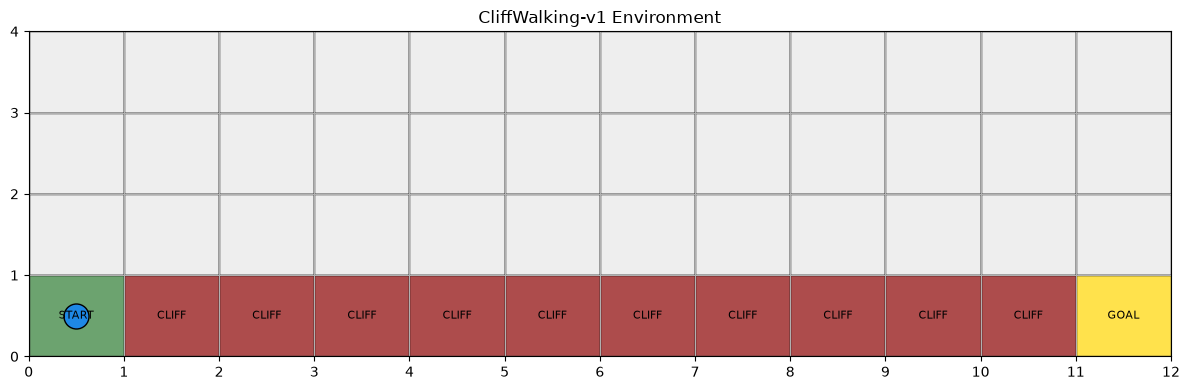

In [19]:
def draw_cliffwalking_grid(rows, cols, cliff_states, start_state, goal_state,
                           agent_state=None, title="CliffWalking-v1 Environment"):
    """Pure-matplotlib rendering of the CliffWalking grid (no pygame dependency)."""
    fig, ax = plt.subplots(figsize=(cols, rows))

    for s in range(rows * cols):
        r, c = divmod(s, cols)
        if s in cliff_states:
            color, label = "#8B0000", "CLIFF"
        elif s == start_state:
            color, label = "#2E7D32", "START"
        elif s == goal_state:
            color, label = "#FFD700", "GOAL"
        else:
            color, label = "#EEEEEE", ""
        ax.add_patch(plt.Rectangle((c, rows - 1 - r), 1, 1, facecolor=color,
                                    edgecolor="black", alpha=0.7 if color != "#EEEEEE" else 1.0))
        if label:
            ax.text(c + 0.5, rows - 1 - r + 0.5, label, ha="center", va="center", fontsize=8)

    if agent_state is not None:
        ar, ac = divmod(agent_state, cols)
        ax.plot(ac + 0.5, rows - 1 - ar + 0.5, marker="o", markersize=18,
                color="#1E88E5", markeredgecolor="black")

    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_xticks(range(cols + 1))
    ax.set_yticks(range(rows + 1))
    ax.grid(True)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

render_env = gym.make("CliffWalking-v1")
state, info = render_env.reset(seed=RNG_SEED)
render_env.close()

draw_cliffwalking_grid(GRID_ROWS, GRID_COLS, CLIFF_STATES, START_STATE, GOAL_STATE, agent_state=state)

Environment: Shows the 4×12 CliffWalking grid with the start, cliff, and goal states.

Success Rate Comparison:
500 training episodes: 100.0%
1000 training episodes: 100.0%
2000 training episodes: 100.0%
5000 training episodes: 100.0%
10000 training episodes: 100.0%

All configurations achieved the same success rate.


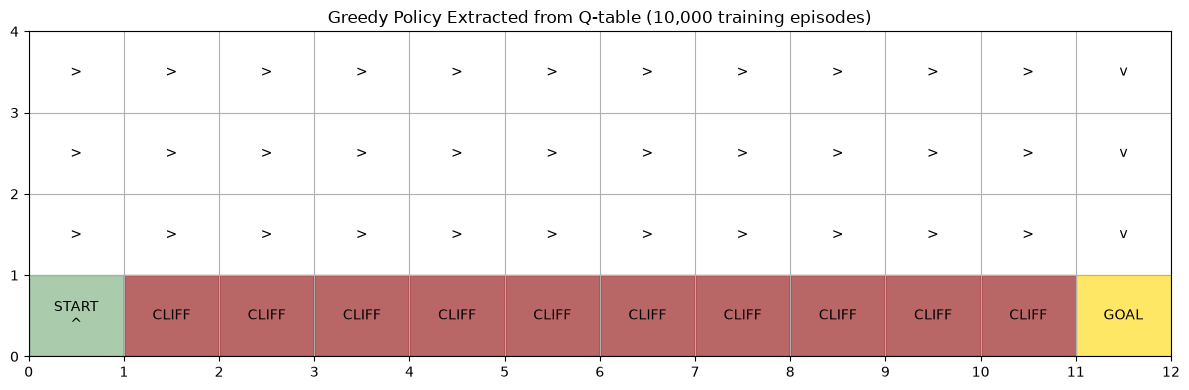

In [20]:
# Compare the success rates of all configurations

print("Success Rate Comparison:")

for n, rate in zip(EPISODE_CONFIGS, success_rates):
    print(f"{n} training episodes: {rate:.1f}%")

if len(set(success_rates)) == 1:
    print("\nAll configurations achieved the same success rate.")
else:
    best_index = success_rates.index(max(success_rates))
    best_n_episodes = EPISODE_CONFIGS[best_index]
    print(f"\nHighest success rate: {best_n_episodes} training episodes")


# Plot the greedy policy learned after 10,000 training episodes

def plot_policy_grid(Qtable, rows, cols, cliff_states, start_state, goal_state):
    fig, ax = plt.subplots(figsize=(cols, rows))

    for s in range(rows * cols):
        r, c = divmod(s, cols)

        if s in cliff_states:
            ax.add_patch(
                plt.Rectangle(
                    (c, rows - 1 - r), 1, 1,
                    color="#8B0000", alpha=0.6
                )
            )
            label = "CLIFF"

        elif s == start_state:
            ax.add_patch(
                plt.Rectangle(
                    (c, rows - 1 - r), 1, 1,
                    color="#2E7D32", alpha=0.4
                )
            )
            label = "START\n" + ACTION_ARROWS[greedy_policy(Qtable, s)]

        elif s == goal_state:
            ax.add_patch(
                plt.Rectangle(
                    (c, rows - 1 - r), 1, 1,
                    color="#FFD700", alpha=0.6
                )
            )
            label = "GOAL"

        else:
            action = greedy_policy(Qtable, s)
            label = ACTION_ARROWS[action]

        ax.text(
            c + 0.5,
            rows - 1 - r + 0.5,
            label,
            ha="center",
            va="center",
            fontsize=10
        )

    ax.set_xlim(0, cols)
    ax.set_ylim(0, rows)
    ax.set_xticks(range(cols + 1))
    ax.set_yticks(range(rows + 1))
    ax.grid(True)
    ax.set_title(
        "Greedy Policy Extracted from Q-table (10,000 training episodes)"
    )
    plt.tight_layout()
    plt.show()


# Use the Q-table stored specifically for the 10,000-episode configuration
Qtable_10000 = results[10000]["Qtable"]

plot_policy_grid(
    Qtable_10000,
    GRID_ROWS,
    GRID_COLS,
    CLIFF_STATES,
    START_STATE,
    GOAL_STATE
)

Greedy Policy: Shows the learned actions directing the agent toward the goal while avoiding the cliff.

In [21]:
!pip install imageio


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [22]:
import imageio

def record_agent_gif(Qtable, env_id, out_path, max_steps=200, fps=3):
    env = gym.make(env_id, render_mode="rgb_array")
    state, info = env.reset(seed=RNG_SEED)
    frames = [env.render()]

    for step in range(max_steps):
        action = greedy_policy(Qtable, state)
        state, reward, terminated, truncated, info = env.step(action)
        frames.append(env.render())
        if terminated or truncated:
            break

    env.close()
    imageio.mimsave(out_path, frames, fps=fps)
    print(f"Saved GIF with {len(frames)} frames to {out_path}")
    return out_path

gif_path = record_agent_gif(Qtable_10000, "CliffWalking-v1", "cliffwalking_policy.gif")
print(gif_path)

Saved GIF with 14 frames to cliffwalking_policy.gif
cliffwalking_policy.gif


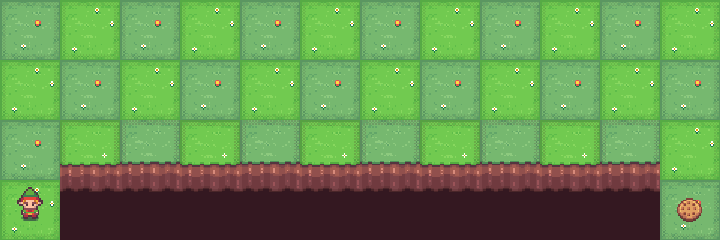

In [23]:
from IPython.display import Image
Image(filename=gif_path)

## Summary

- Five Q-learning agents were trained independently on `CliffWalking-v1` for 500 to 10,000 episodes using an epsilon-greedy policy.
- Training rewards were recorded to compare cumulative and rolling average rewards.
- Each policy was tested for 100 episodes using greedy actions, with success based on reaching the goal.
- The results show that increasing the number of training episodes improves learning performance, with the average training reward becoming less negative over time, while all configurations achieved a 100% success rate.

## SELF LEARNING

Training (10 episodes): 100%|█████████████████| 10/10 [00:00<00:00, 374.41it/s]


  10 episodes -> mean reward: -200.00, std:  0.00, success rate:   0.00%


Training (25 episodes): 100%|█████████████████| 25/25 [00:00<00:00, 433.95it/s]

  25 episodes -> mean reward: -200.00, std:  0.00, success rate:   0.00%

Training (50 episodes): 100%|█████████████████| 50/50 [00:00<00:00, 426.14it/s]


  50 episodes -> mean reward: -1982.00, std:  0.00, success rate:   0.00%


... (16 outputs left out)

Training (450 episodes): 100%|██████████████| 450/450 [00:00<00:00, 473.96it/s]


 450 episodes -> mean reward:  -13.00, std:  0.00, success rate: 100.00%


Training (500 episodes): 100%|██████████████| 500/500 [00:00<00:00, 517.86it/s]


 500 episodes -> mean reward:  -13.00, std:  0.00, success rate: 100.00%

Success rate first reaches 100% at 100 training episodes.


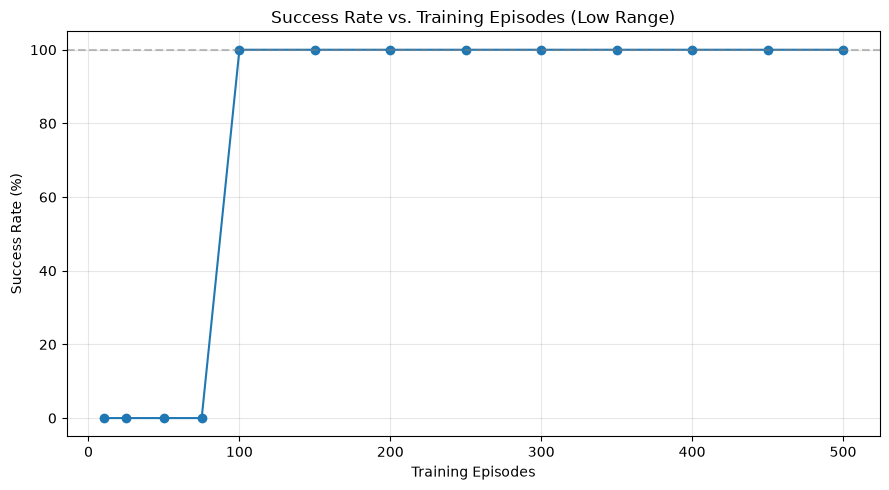

In [24]:
# Fine-grained sweep over LOW episode counts to find where success rate first reaches 100%
LOW_EPISODE_CONFIGS = [10, 25, 50, 75, 100, 150, 200, 250, 300, 350, 400, 450, 500]

low_results = {}

eval_rng_low = np.random.default_rng(RNG_SEED)
eval_seeds_low = eval_rng_low.integers(low=0, high=1_000_000, size=n_eval_episodes).tolist()

env_low = gym.make("CliffWalking-v1")

for n_episodes in LOW_EPISODE_CONFIGS:
    Qtable = initialize_q_table(state_space, action_space)

    Qtable, episode_rewards = train(
        n_episodes, min_epsilon, max_epsilon, decay_rate,
        env_low, max_steps, Qtable, learning_rate, gamma
    )

    mean_reward, std_reward, success_rate = evaluate_agent(
        env_low, max_steps, n_eval_episodes, Qtable, seeds=eval_seeds_low
    )

    low_results[n_episodes] = {
        "Qtable": Qtable,
        "episode_rewards": episode_rewards,
        "mean_reward": mean_reward,
        "std_reward": std_reward,
        "success_rate": success_rate,
    }

    print(f"{n_episodes:>4} episodes -> mean reward: {mean_reward:7.2f}, "
          f"std: {std_reward:5.2f}, success rate: {success_rate:6.2f}%")

env_low.close()

# Find the first config where success rate hits 100%
first_100 = next((n for n in LOW_EPISODE_CONFIGS if low_results[n]["success_rate"] == 100.0), None)
if first_100:
    print(f"\nSuccess rate first reaches 100% at {first_100} training episodes.")
else:
    print("\n100% success rate not reached within this range.")

# Plot success rate vs. number of low-range training episodes
plt.figure(figsize=(9, 5))
rates = [low_results[n]["success_rate"] for n in LOW_EPISODE_CONFIGS]
plt.plot(LOW_EPISODE_CONFIGS, rates, marker="o")
plt.axhline(100, color="gray", linestyle="--", alpha=0.5)
plt.xlabel("Training Episodes")
plt.ylabel("Success Rate (%)")
plt.title("Success Rate vs. Training Episodes (Low Range)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

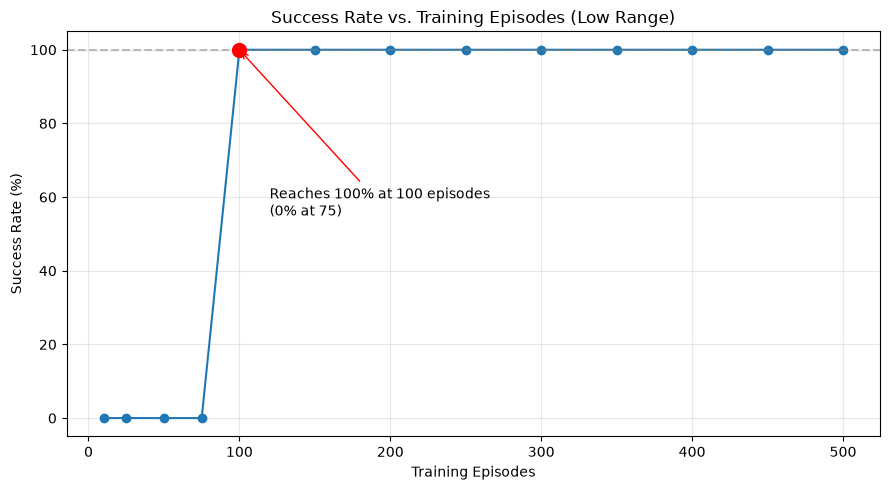

In [25]:
first_100 = next((n for n in LOW_EPISODE_CONFIGS if low_results[n]["success_rate"] == 100.0), None)
first_100_idx = LOW_EPISODE_CONFIGS.index(first_100)
last_below_100 = LOW_EPISODE_CONFIGS[first_100_idx - 1]

rates = [low_results[n]["success_rate"] for n in LOW_EPISODE_CONFIGS]

plt.figure(figsize=(9, 5))
plt.plot(LOW_EPISODE_CONFIGS, rates, marker="o")
plt.axhline(100, color="gray", linestyle="--", alpha=0.5)

# Mark the exact transition point
plt.scatter([first_100], [100], color="red", zorder=5, s=100)
plt.annotate(f"Reaches 100% at {first_100} episodes\n(0% at {last_below_100})",
             xy=(first_100, 100), xytext=(first_100 + 20, 55),
             arrowprops=dict(arrowstyle="->", color="red"))

plt.xlabel("Training Episodes")
plt.ylabel("Success Rate (%)")
plt.title("Success Rate vs. Training Episodes (Low Range)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Inference:** The greedy policy's success rate jumps from 0% to 100% between 75 and 100 training episodes, and stays saturated at 100% for all higher episode counts up to 500.